# 02 · ¿Será bien recibido? Clasificación y umbral por costos
**Responsable:** Persona A

**Pregunta:** con solo lo que se sabe del juego en la tienda (precio, géneros, etiquetas, plataformas, desarrollador…), ¿podemos anticipar si tendrá más de 80 % de reseñas positivas?

**Entrada:** `data/processed/juegos.parquet` · **Salida:** `outputs/pred_calidad.csv` (appid, p_bien_recibido) y `outputs/umbral.json`

Reglas que seguimos:
- **Sin fuga de datos:** ninguna columna derivada de reseñas, owners, playtime o metacritic (`C.COLUMNAS_PROHIBIDAS`). `construir_X` lo verifica con un `assert`.
- Todo el preprocesamiento va **dentro del Pipeline** (escalado y *target encoding* del desarrollador se ajustan solo con los datos de entrenamiento de cada fold).
- Validación cruzada estratificada de 5 folds sobre el 80 %; el **20 % de examen se usa una sola vez**, al final.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, RocCurveDisplay)
from sklearn.inspection import permutation_importance

from src import config as C
from src.datos import cargar_juegos
from src.features import construir_X, NUMERICAS, CATEGORICAS

df = cargar_juegos()
X = construir_X(df)
y = df["bien_recibido"]
print(X.shape, f"positivos: {y.mean():.1%}")

(44568, 359) positivos: 52.8%


## 1. Separar el examen
El 20 % se aparta ahora y no se mira hasta la sección 4.

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=C.SEMILLA)
print(f"entrenamiento: {len(X_tr):,}  ·  examen: {len(X_te):,}")

entrenamiento: 35,654  ·  examen: 8,914


## 2. Comparar modelos con validación cruzada
- **Perezoso** (`DummyClassifier`): siempre dice la clase más común. Es la línea base que hay que superar.
- **Regresión logística**, **Random Forest** y **boosting** (`HistGradientBoostingClassifier`).

In [3]:
otras = [c for c in X.columns if c not in NUMERICAS + CATEGORICAS]

def pipeline(modelo):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUMERICAS),
        ("te", TargetEncoder(random_state=C.SEMILLA), CATEGORICAS),  # desarrollador / publicador
        ("bin", "passthrough", otras),
    ])
    return Pipeline([("pre", pre), ("modelo", modelo)])

modelos = {
    "perezoso": DummyClassifier(strategy="most_frequent"),
    "logistica": LogisticRegression(max_iter=2000, C=0.5),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=C.SEMILLA),
    "boosting": HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, random_state=C.SEMILLA),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEMILLA)

filas = []
for nombre, modelo in modelos.items():
    r = cross_validate(pipeline(modelo), X_tr, y_tr, cv=cv,
                       scoring=["roc_auc", "precision", "recall", "accuracy"])
    filas.append({"modelo": nombre,
                  **{m: r[f"test_{m}"].mean() for m in ["roc_auc", "precision", "recall", "accuracy"]},
                  "auc_std": r["test_roc_auc"].std()})
resultados_cv = pd.DataFrame(filas).set_index("modelo").round(3)
resultados_cv.to_csv(C.OUTPUTS / "02_resultados_cv.csv")
resultados_cv

,roc_auc,precision,recall,accuracy,auc_std
modelo,,,,,
perezoso,0.500,0.528,1.000,0.528,0.000
logistica,0.776,0.719,0.728,0.706,0.004
random_forest,0.795,0.721,0.771,0.722,0.004
boosting,0.799,0.732,0.757,0.726,0.004


In [4]:
mejor = resultados_cv["roc_auc"].idxmax()
print("Modelo elegido (mayor AUC en CV):", mejor)

Modelo elegido (mayor AUC en CV): boosting


## 3. Elegir el umbral según el costo
El 0.5 es una costumbre, no una decisión. Para nuestro jugador:
- **Comprar un juego malo** (falso positivo) = pierde el dinero completo → costo `C.COSTO_COMPRAR_MALO = 1`.
- **Perderse un juego bueno** (falso negativo) = duele menos, porque en la oferta hay muchos sustitutos buenos → `C.COSTO_PERDER_BUENO = 0.5`.

Para no tocar el examen, el umbral se elige con las **predicciones fuera de fold** (`cross_val_predict`) del conjunto de entrenamiento.

umbral = 0.66  ·  costo 0.187 vs 0.210 con 0.5


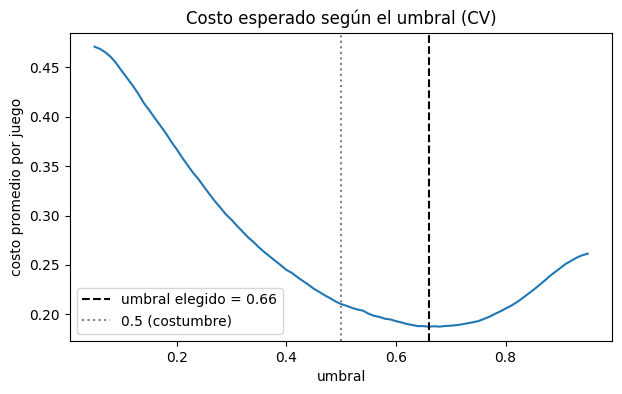

In [5]:
p_oof = cross_val_predict(pipeline(modelos[mejor]), X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]

def costo_promedio(y_true, p, umbral, c_fp=C.COSTO_COMPRAR_MALO, c_fn=C.COSTO_PERDER_BUENO):
    pred = p >= umbral
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    return (c_fp * fp + c_fn * fn) / len(y_true)

umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
costos = np.array([costo_promedio(y_tr.values, p_oof, u) for u in umbrales])
umbral = float(umbrales[costos.argmin()])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(umbrales, costos)
ax.axvline(umbral, color="k", ls="--", label=f"umbral elegido = {umbral:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="0.5 (costumbre)")
ax.set(xlabel="umbral", ylabel="costo promedio por juego", title="Costo esperado según el umbral (CV)")
ax.legend()
fig.savefig(C.FIGURAS / "02_costo_umbral.png", dpi=120, bbox_inches="tight")
print(f"umbral = {umbral:.2f}  ·  costo {costos.min():.3f} vs {costo_promedio(y_tr.values, p_oof, 0.5):.3f} con 0.5")

**Sensibilidad:** ¿cómo cambia el umbral si perderse un bueno duele más o menos?

In [6]:
sens = []
for c_fn in [0.25, 0.5, 1.0, 2.0]:
    cs = [costo_promedio(y_tr.values, p_oof, u, c_fp=1.0, c_fn=c_fn) for u in umbrales]
    u = umbrales[int(np.argmin(cs))]
    pred = p_oof >= u
    sens.append({"costo_perder_bueno / costo_comprar_malo": c_fn, "umbral": u,
                 "precision": precision_score(y_tr, pred), "recall": recall_score(y_tr, pred),
                 "% de juegos que pasan": pred.mean()})
pd.DataFrame(sens).round(3)

,costo_perder_bueno / costo_comprar_malo,umbral,precision,recall,% de juegos que pasan
0,0.25,0.79,0.874,0.325,0.196
1,0.50,0.66,0.805,0.561,0.367
2,1.00,0.50,0.732,0.757,0.546
3,2.00,0.33,0.654,0.899,0.725


## 4. Evaluación final en el examen (una sola vez)
Se entrena el modelo elegido con todo el 80 % y se evalúa en el 20 % que no se había tocado.

In [7]:
final = pipeline(modelos[mejor]).fit(X_tr, y_tr)
p_te = final.predict_proba(X_te)[:, 1]

def metricas(u):
    pred = p_te >= u
    return {"AUC": roc_auc_score(y_te, p_te), "precision": precision_score(y_te, pred),
            "recall": recall_score(y_te, pred), "accuracy": accuracy_score(y_te, pred),
            "costo": costo_promedio(y_te.values, p_te, u)}

examen = pd.DataFrame({f"umbral {umbral:.2f}": metricas(umbral), "umbral 0.50": metricas(0.5),
                       "perezoso": {"AUC": 0.5, "precision": y_te.mean(), "recall": 1.0,
                                    "accuracy": y_te.mean(), "costo": C.COSTO_COMPRAR_MALO * (1 - y_te.mean())}}).round(3)
examen.to_csv(C.OUTPUTS / "02_resultados_examen.csv")
examen

,umbral 0.66,umbral 0.50,perezoso
AUC,0.811,0.811,0.500
precision,0.815,0.736,0.527
recall,0.577,0.767,1.000
accuracy,0.708,0.732,0.527
costo,0.180,0.206,0.473


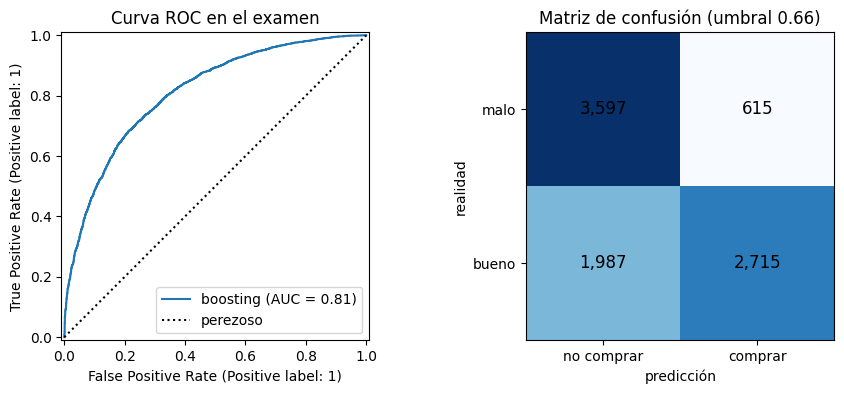

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_te, p_te, ax=axes[0], name=mejor)
axes[0].plot([0, 1], [0, 1], "k:", label="perezoso")
axes[0].set_title("Curva ROC en el examen"); axes[0].legend()

cm = confusion_matrix(y_te, p_te >= umbral)
axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center", fontsize=12)
axes[1].set_xticks([0, 1], ["no comprar", "comprar"]); axes[1].set_yticks([0, 1], ["malo", "bueno"])
axes[1].set(xlabel="predicción", ylabel="realidad", title=f"Matriz de confusión (umbral {umbral:.2f})")
fig.savefig(C.FIGURAS / "02_roc_confusion.png", dpi=120, bbox_inches="tight")

### ¿Qué variables pesan más? (importancia por permutación en el examen)

antiguedad_anios             0.0481
publicador                   0.0328
desarrollador                0.0150
log_precio                   0.0051
tag_Pixel Graphics           0.0045
n_idiomas                    0.0037
log_logros                   0.0026
cat_Steam Cloud              0.0025
tag_Classic                  0.0022
tag_Cute                     0.0020
tag_2D                       0.0018
tag_Great Soundtrack         0.0018
tag_Puzzle                   0.0017
cat_Remote Play on Tablet    0.0015
cat_Family Sharing           0.0015
dtype: float64

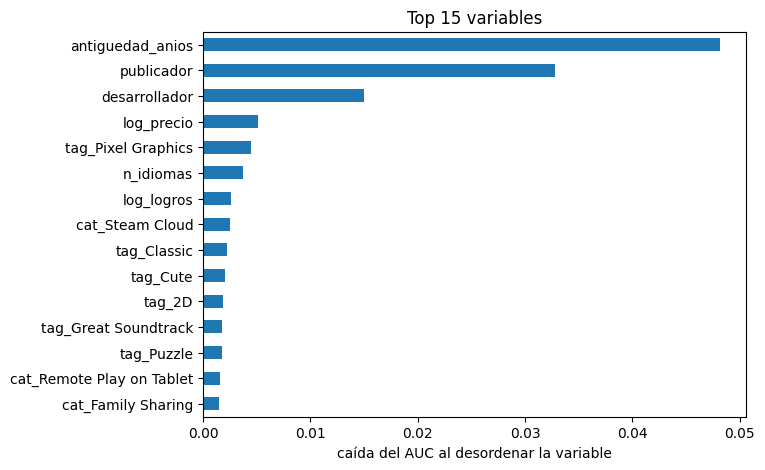

In [9]:
muestra = X_te.sample(3000, random_state=C.SEMILLA)
imp = permutation_importance(final, muestra, y_te.loc[muestra.index], scoring="roc_auc",
                             n_repeats=3, random_state=C.SEMILLA, n_jobs=-1)
importancias = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7, 5))
importancias[::-1].plot.barh(ax=ax)
ax.set(xlabel="caída del AUC al desordenar la variable", title="Top 15 variables")
fig.savefig(C.FIGURAS / "02_importancia.png", dpi=120, bbox_inches="tight")
importancias.round(4)

## 5. Predicciones para la decisión (entrega a Persona C)
Para que ninguna probabilidad venga de un modelo que ya vio ese juego:
- juegos de **entrenamiento** → probabilidad fuera de fold (`p_oof`)
- juegos de **examen** → probabilidad del modelo final (que no los vio)

In [10]:
pred = pd.concat([
    pd.DataFrame({"appid": df.loc[X_tr.index, "appid"], "p_bien_recibido": p_oof, "en_examen": False}),
    pd.DataFrame({"appid": df.loc[X_te.index, "appid"], "p_bien_recibido": p_te, "en_examen": True}),
])
pred["pasa_umbral"] = pred["p_bien_recibido"] >= umbral
pred.to_csv(C.OUTPUTS / "pred_calidad.csv", index=False)

(C.OUTPUTS / "umbral.json").write_text(json.dumps({
    "modelo": mejor, "umbral": umbral,
    "costo_comprar_malo": C.COSTO_COMPRAR_MALO, "costo_perder_bueno": C.COSTO_PERDER_BUENO,
    "auc_examen": round(float(roc_auc_score(y_te, p_te)), 4),
}, indent=2))
print(f"{len(pred):,} juegos guardados · pasan el umbral: {pred['pasa_umbral'].mean():.1%}")
pred.head()

44,568 juegos guardados · pasan el umbral: 36.9%


,appid,p_bien_recibido,en_examen,pasa_umbral
40961,1857740,0.544009,False,False
15703,1127820,0.685212,False,True
31488,355410,0.324611,False,False
22939,925100,0.111376,False,False
33214,2416460,0.343784,False,False


## Conclusiones

**1. Sí se puede anticipar la calidad, con un poder moderado.** El boosting llega a **AUC ≈ 0.80 en CV y 0.81 en el examen**, frente a 0.50 del modelo perezoso. Random Forest queda casi igual (0.795) y la regresión logística un poco atrás (0.776). La diferencia CV → examen es pequeña, así que no hay señales de sobreajuste.

**2. El umbral cambia la decisión.** Con nuestros costos (comprar un malo = 1, perder un bueno = 0.5) el umbral óptimo es **0.66, no 0.5**. En el examen:
- la **precision sube de 0.74 a 0.82**: de cada 10 juegos que el modelo recomienda, 8 son realmente bien recibidos;
- a cambio, el recall baja (0.77 → 0.58): dejamos pasar varios buenos, lo cual es aceptable porque en la oferta sobran alternativas;
- el **costo esperado baja de 0.206 a 0.180** por juego (el perezoso cuesta 0.473).

La tabla de sensibilidad muestra que, si el jugador fuera más tolerante a perderse buenos (0.25), el umbral subiría a ~0.79 y solo pasaría el 20 % de los juegos.

**3. Qué pesa más:**
- **Antigüedad:** los juegos viejos que siguen en la tienda con reseñas tienden a ser mejores (*sesgo de supervivencia*: los malos desaparecen o nadie los reseña). Esto también importa para la pregunta causal del notebook 04.
- **Publicador y desarrollador:** la reputación del estudio predice bastante.
- Después vienen el precio, los idiomas, los logros y algunas etiquetas (Pixel Graphics, Cute, Puzzle, Great Soundtrack).

**Limitaciones:**
- Las **etiquetas las ponen los usuarios** después del lanzamiento. Algunas ("Great Soundtrack", "Classic") reflejan en parte la opinión de los jugadores, así que el modelo es algo optimista para juegos *recién* lanzados.
- El *target encoding* del desarrollador favorece a estudios con historial. Para estudios nuevos, el modelo se apoya en el resto de variables.
- "Bien recibido" (> 80 %) es un corte arbitrario: un juego con 79 % cuenta como "malo".

**Entrega a Persona C:** `outputs/pred_calidad.csv` (44,568 juegos con `p_bien_recibido` y `pasa_umbral`) y `outputs/umbral.json`.